
## H1. Relación entre las horas de escucha musical y la ansiedad
¿Las personas que escuchan más horas de música al día tienden a presentar niveles de ansiedad diferentes?

En esta primera hipótesis queremos estudiar si existe una relación entre la cantidad de horas que una persona escucha música diariamente y su nivel de ansiedad autodeclarado.

Para ello, seleccionamos las variables `Hours per day` y `Anxiety` y examinamos sus características antes de realizar el análisis estadístico.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../data/mxmh_preparado02.csv")

#  variables de la primera 
df_h1 = df[["Hours per day", "Anxiety"]].copy()

print(df_h1.info())
display(df_h1.describe())

<class 'pandas.DataFrame'>
RangeIndex: 736 entries, 0 to 735
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Hours per day  736 non-null    float64
 1   Anxiety        736 non-null    float64
dtypes: float64(2)
memory usage: 11.6 KB
None


,Hours per day,Anxiety
count,736.000000,736.000000
mean,3.572758,5.837636
std,3.028199,2.793054
min,0.000000,0.000000
25%,2.000000,4.000000
50%,3.000000,6.000000
75%,5.000000,8.000000
max,24.000000,10.000000


### 2. Visualización de la relación entre horas de escucha y ansiedad

Para explorar la posible relación entre ambas variables utilizamos un gráfico de dispersión (*scatterplot*).

Este gráfico permite representar las horas diarias de escucha musical en el eje X y los niveles de ansiedad autodeclarados en el eje Y.

El objetivo es observar si existe alguna tendencia visual entre ambas variables y detectar posibles valores extremos que puedan influir en el análisis.

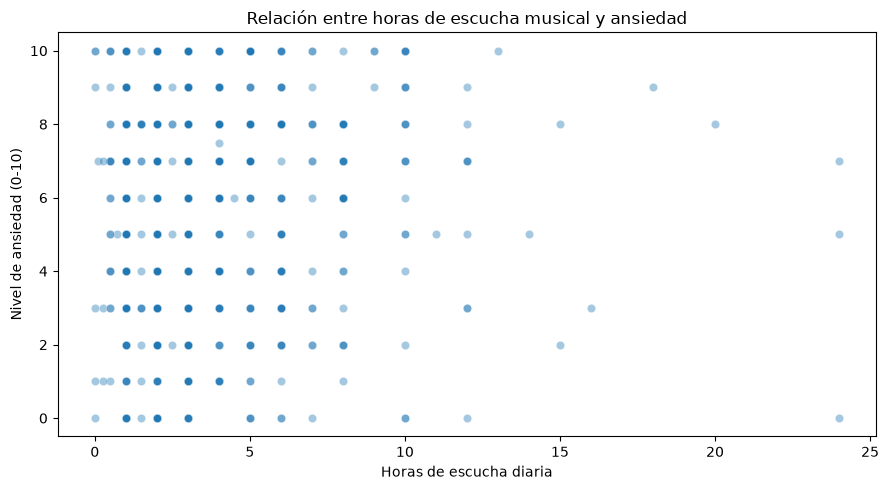

In [5]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_h1,
    x="Hours per day",
    y="Anxiety",
    alpha=0.4
)

plt.title("Relación entre horas de escucha musical y ansiedad")
plt.xlabel("Horas de escucha diaria")
plt.ylabel("Nivel de ansiedad (0-10)")

plt.tight_layout()
plt.show()

### Conclusión H1: horas de escucha y ansiedad

El gráfico de dispersión muestra que los niveles de ansiedad son muy variados, incluso entre personas que escuchan música durante un número similar de horas.

La mayoría de las observaciones se concentran entre 0 y 8 horas de escucha diaria, sin que se aprecie una tendencia claramente creciente o decreciente en los niveles de ansiedad.

**Por tanto, no se observa una relación visual clara entre las horas de escucha musical y la ansiedad en este conjunto de datos.**

## H2. Género musical favorito y niveles de depresión

En esta segunda hipótesis queremos explorar si existen diferencias en los niveles de depresión autodeclarados según el género musical favorito de los participantes.

Para ello, agruparemos los datos por género musical y calcularemos la puntuación media de depresión y el número de participantes de cada grupo.

Esto nos permitirá comparar los diferentes géneros teniendo en cuenta que algunos tienen muchos más participantes que otros.

### 1. Seleccionar y agrupar los datos

In [7]:
# variables de H2
df_h2 = df[["Fav genre", "Depression"]].copy()

resumen_h2 = df_h2.groupby("Fav genre")["Depression"].agg(
    ["count", "mean"]
)

resumen_h2 = resumen_h2.sort_values(
    by="mean",
    ascending=False
)

display(resumen_h2.round(2))

,count,mean
Fav genre,,
Lofi,10,6.60
Hip hop,35,5.80
EDM,37,5.24
Rock,188,5.24
Metal,88,5.07
Folk,30,5.07
Jazz,20,4.50
Pop,114,4.49
Video game music,44,4.48


### Visualización de los niveles medios de depresión por género musical

Representamos mediante un gráfico de barras la puntuación media de depresión correspondiente a cada género musical.

El gráfico permite comparar visualmente los grupos y observar cuáles presentan las puntuaciones medias más altas y más bajas.

Estas diferencias son descriptivas y no implican que escuchar un determinado género musical provoque depresión.

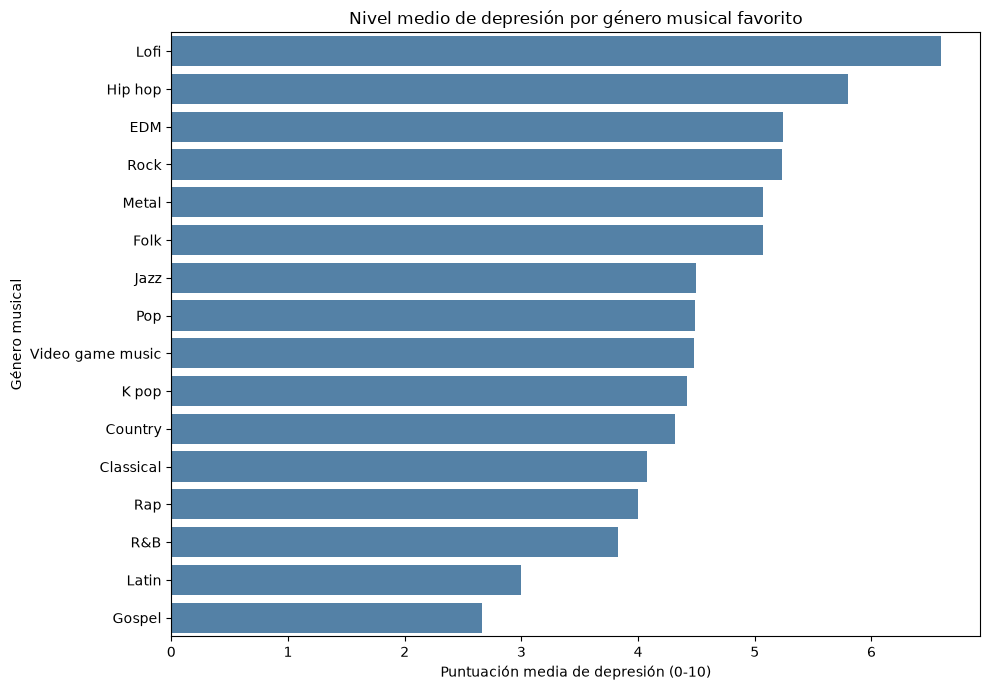

In [8]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=resumen_h2.reset_index(),
    x="mean",
    y="Fav genre",
    color="steelblue",
    errorbar=None
)

plt.title("Nivel medio de depresión por género musical favorito")
plt.xlabel("Puntuación media de depresión (0-10)")
plt.ylabel("Género musical")

plt.tight_layout()
plt.show()

### Conclusión H2: género musical favorito y depresión

El análisis muestra diferencias en las puntuaciones medias de depresión según el género musical favorito.

Los participantes que prefieren Lofi y Hip hop presentan las medias más elevadas, mientras que Gospel, Latin y R&B registran las más bajas.

Sin embargo, algunos géneros tienen un número reducido de participantes, por lo que sus resultados pueden ser menos representativos.

**En conclusión, se observan diferencias descriptivas entre géneros musicales, pero no podemos afirmar que exista una relación causal entre las preferencias musicales y los niveles de depresión.**

## H3. Frecuencia de escucha musical y salud mental

**Pregunta:** ¿cómo varían las puntuaciones de ansiedad, depresión, insomnio y TOC según la frecuencia con la que los participantes escuchan distintos géneros musicales?

En esta hipótesis analizamos cómo varían los indicadores de ansiedad, depresión, insomnio y TOC según la frecuencia con la que los participantes escuchan diferentes géneros musicales.

Durante la preparación del dataset se transformamoron las categorías de frecuencia en valores numéricos del 0 al 3.

Utilizaremos estos valores para agrupar los participantes según sus hábitos de escucha y comparar las puntuaciones medias de los cuatro indicadores de salud mental.

In [9]:
# columnas de frecuencia musical
columnas_frecuencia = [
    col for col in df.columns
    if col.startswith("Frequency [")
]

indicadores = ["Anxiety", "Depression", "Insomnia", "OCD"]

# dataframe para H3
df_h3 = df[columnas_frecuencia + indicadores].copy()

print(f"Géneros musicales analizados: {len(columnas_frecuencia)}")
print(f"Participantes: {len(df_h3)}")

display(df_h3.head())

Géneros musicales analizados: 16
Participantes: 736


,Frequency [Classical],Frequency [Country],Frequency [EDM],Frequency [Folk],Frequency [Gospel],Frequency [Hip hop],Frequency [Jazz],Frequency [K pop],Frequency [Latin],Frequency [Lofi],Frequency [Metal],Frequency [Pop],Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD
0,1,0,1,0,0,2,0,3,3,1,0,3,2,3,0,2,3.0,0.0,1.0,0.0
1,2,0,0,1,2,1,3,1,2,1,0,2,2,1,3,1,7.0,2.0,2.0,1.0
2,0,0,3,0,0,1,1,3,0,2,2,1,0,1,1,3,7.0,7.0,10.0,2.0
3,2,0,0,1,2,0,3,2,3,2,0,2,2,0,0,0,9.0,7.0,3.0,3.0
4,0,0,1,0,1,3,0,3,2,2,0,2,3,3,0,1,7.0,2.0,5.0,9.0


### Comparación entre frecuencias de escucha

Para cada género musical, comparamos las puntuaciones medias de los participantes que indican que nunca lo escuchan (0) con las de quienes lo escuchan muy frecuentemente (3).

Calculamos la diferencia entre ambas medias para cada indicador psicológico.

Una diferencia positiva significa que el grupo de escucha muy frecuente presenta una puntuación media mayor. Una diferencia negativa significa que presenta una puntuación menor.

Esta comparación es descriptiva y no permite establecer relaciones causales.

In [11]:
resultados_h3 = []

for genero in columnas_frecuencia:

    grupo = df_h3.groupby(genero)[indicadores].mean()

    if 0 in grupo.index and 3 in grupo.index:

        diferencia = grupo.loc[3] - grupo.loc[0]
        diferencia.name = genero.replace("Frequency [", "").replace("]", "")

        resultados_h3.append(diferencia)

resumen_h3 = pd.DataFrame(resultados_h3)

display(resumen_h3.round(2))

,Anxiety,Depression,Insomnia,OCD
Classical,-0.62,-0.23,0.71,-0.12
Country,-0.06,-0.15,-0.71,0.17
EDM,0.29,0.68,0.78,0.80
Folk,0.50,0.94,0.53,0.05
Gospel,-0.30,-1.01,-0.27,-0.28
Hip hop,0.32,0.85,0.44,0.58
Jazz,0.05,0.58,0.88,-0.01
K pop,0.31,-0.28,0.00,0.23
Latin,0.30,0.19,0.11,0.28
Lofi,0.15,0.03,0.76,0.26


### Visualización de las diferencias mediante un mapa de calor

Utilizamos un mapa de calor para representar las diferencias entre las puntuaciones medias de los participantes que escuchan muy frecuentemente cada género y las de quienes nunca lo escuchan.

Los valores positivos indican puntuaciones medias superiores en el grupo de escucha frecuente y los negativos indican puntuaciones inferiores.

Este gráfico permite identificar visualmente qué géneros presentan las mayores diferencias descriptivas en los cuatro indicadores.

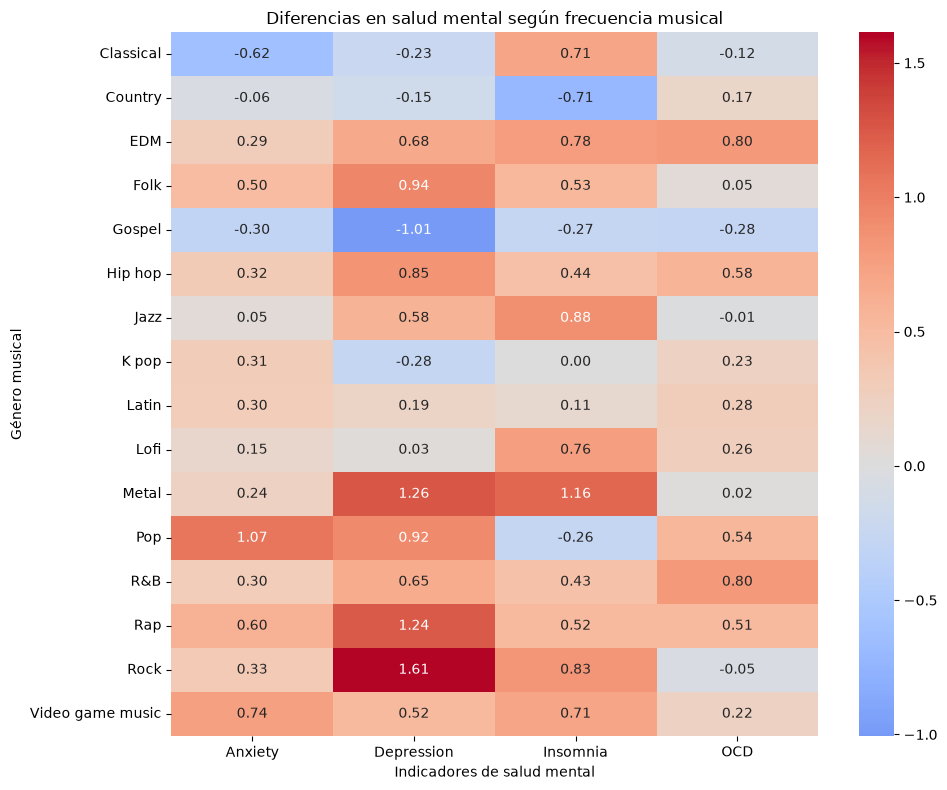

In [12]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    resumen_h3,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Diferencias en salud mental según frecuencia musical")
plt.xlabel("Indicadores de salud mental")
plt.ylabel("Género musical")

plt.tight_layout()
plt.show()

### Conclusión H3: frecuencia de escucha musical y salud mental

El mapa de calor muestra diferencias en las puntuaciones medias de salud mental entre los participantes que escuchan muy frecuentemente determinados géneros musicales y aquellos que nunca los escuchan.

Las diferencias más destacadas aparecen en depresión para Rock (+1,61), Metal (+1,26) y Rap (+1,24). También encontramos diferencias en insomnio para Metal (+1,16) y en ansiedad para Pop (+1,07).

Sin embargo, estas diferencias no siguen un patrón uniforme entre todos los géneros ni entre los cuatro indicadores psicológicos.

**En conclusión, se observan diferencias descriptivas relacionadas con la frecuencia de escucha de algunos géneros musicales, pero no podemos establecer que estos hábitos sean la causa de las puntuaciones de salud mental.**

Además, los resultados deben interpretarse con precaución, ya que no hemos comparado el número de participantes de cada grupo.

**Matiz importante:** El heatmap representa diferencias de medias, no correlaciones.

También estamos comparando únicamente dos categorías de frecuencia (Never y Very frequently), dejando fuera las dos intermedias para esta comparación concreta.

## H4. Efectos percibidos de la música y salud mental

**Pregunta:** ¿presentan diferentes niveles de ansiedad, depresión, insomnio y TOC las personas según cómo perciben los efectos de la música en su salud mental?

En esta última hipótesis queremos analizar si existen diferencias en los niveles de ansiedad, depresión, insomnio y TOC según cómo perciben los participantes los efectos de la música en su salud mental.

Para ello, agruparemos los participantes según las respuestas de `Music effects` y calcularemos las puntuaciones medias de los cuatro indicadores psicológicos.

El objetivo es realizar una comparación descriptiva entre los tres grupos.

In [13]:
# variables de H4
columnas_h4 = [
    "Music effects",
    "Anxiety",
    "Depression",
    "Insomnia",
    "OCD"
]

df_h4 = df[columnas_h4].dropna().copy()

resumen_h4 = df_h4.groupby("Music effects")[
    ["Anxiety", "Depression", "Insomnia", "OCD"]
].mean()

display(resumen_h4.round(2))

,Anxiety,Depression,Insomnia,OCD
Music effects,,,,
Improve,6.05,4.86,3.76,2.72
No effect,5.12,4.38,3.67,2.36
Worsen,6.76,7.18,4.53,3.12


### Visualización de los efectos percibidos

Utilizamos un gráfico de barras agrupadas para comparar las puntuaciones medias de ansiedad, depresión, insomnio y TOC entre los tres grupos de participantes.

Esta representación permite observar qué indicadores presentan mayores diferencias según la percepción de los efectos de la música.

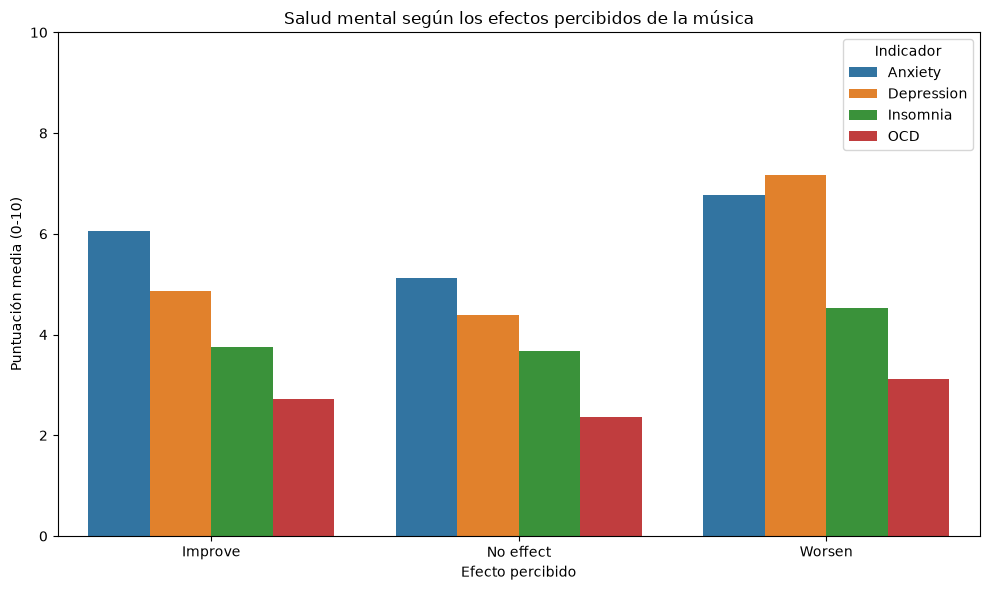

In [14]:

resumen_h4_grafico = resumen_h4.reset_index().melt(
    id_vars="Music effects",
    var_name="Indicador",
    value_name="Puntuación media"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=resumen_h4_grafico,
    x="Music effects",
    y="Puntuación media",
    hue="Indicador",
    errorbar=None
)

plt.title("Salud mental según los efectos percibidos de la música")
plt.xlabel("Efecto percibido")
plt.ylabel("Puntuación media (0-10)")
plt.ylim(0, 10)

plt.legend(title="Indicador")
plt.tight_layout()
plt.show()

### Conclusión H4: efectos percibidos de la música y salud mental

El análisis muestra diferencias en los niveles medios de ansiedad, depresión, insomnio y TOC según los efectos que los participantes atribuyen a la música.

El grupo `Worsen` presenta las puntuaciones más elevadas en los cuatro indicadores, destacando la depresión (7,18). Por otro lado, el grupo `No effect` presenta las medias más bajas.

Sin embargo, existe un importante desequilibrio en el número de participantes: `Improve` cuenta con 542 respuestas, `No effect` con 169 y `Worsen` únicamente con 17.

**Por tanto, aunque observamos diferencias en nuestra muestra, debemos interpretar especialmente los resultados de `Worsen` con precaución debido a su reducido tamaño.**

Estos resultados son descriptivos y no permiten establecer relaciones causales entre la música y la salud mental.